# Image-Inspired Story Creator — Dataset and Runtime Feasibility

**Author:** Ashwin Parthasarathy  
**Evidence collected:** November 11, 2026  
**Stage:** foundation checks; no production caption model has been trained.

## Purpose and boundaries

Determine whether a real caption dataset and the proposed local model components
are usable on an Apple M5 Pro with 24 GiB unified memory before full implementation.
The eventual product flow is **photograph → automated caption → user-approved,
editable premise → separately pretrained storyteller → clearly labeled fiction**.
This notebook checks feasibility, not end-to-end product quality or final rubric compliance.

| Component | Implement, train, or reuse? |
|---|---|
| Image encoder | Reuse frozen ImageNet-pretrained ResNet18 as a feature extractor |
| Caption decoder | Implement and train a randomly initialized Transformer; only synthetic checks exist here |
| Story model | Reuse Qwen2.5-1.5B-Instruct for local inference; no story-model training is claimed |
| Application | Planned local browser interface; Gradio imports, but no application has been built |

**Dataset non-reuse:** the author confirmed that COCO has not been used in a previous
capstone submission. This is an author declaration, not something inferred from code.

## Evidence status after cleanup

Outputs below are retained from the uploaded notebook's actual local runs.
**They were not regenerated during editing.** Execution counts are cleared because
cells originally ran across kernel restarts and out of visual order. Original cell
indices and counts are retained in cell metadata for traceability. Newly added setup
and resource-cleanup cells have no historical output.

The revised prompt is now placed before its matching saved story. The failed online
model-loading cell, transient widgets, repeated tracebacks, and empty cell are removed;
the download failure and recovery are documented in Section 8. The first story's full
text is not present in the uploaded notebook and is not reconstructed here.

## Reading order

1. Setup and environment
2. Training annotation integrity
3. Recorded-license candidate pool
4. One-image access and caption alignment
5. Final-test metadata counts
6. MPS and caption component checks
7. Synthetic training benchmark
8. Local storyteller loading and generation
9. Findings, proposed allocations, and remaining gates

## Run prerequisites

- Open this notebook in the project's **Image Story Creator (.venv)** kernel.
- Keep `annotations_trainval2017.zip` beside this notebook in `feasibility/`.
- Packages must match the locally captured `requirements-feasibility.txt`; it is
  a separate prerequisite and is not embedded in this notebook.
- The one-image check requires network access. ResNet18 weights may download once
  (approximately 45 MB). The Qwen section loads an exact revision from cache only.
- Restart the kernel, then run from the first cell. Do not insert the exploratory
  kernel restarts used during the original session. The new cleanup cells release
  caption-test objects before loading the storyteller.
- Random initializations were not seeded in the original experiments. Settings are
  preserved; numerical values and timings can vary on rerun.

The notebook is organized for sequential execution but **still requires a clean
local rerun on the target Mac**. It has not been executed on another machine to
claim cross-platform or top-to-bottom reproducibility.


## 1. Setup and environment

**Purpose:** verify the working directory and native project kernel. Set the Hub
progress configuration before importing Transformers or Hugging Face Hub so that
model operations do not use notebook download-progress widgets.

**Input:** active Jupyter kernel and the annotation ZIP in the current directory.  
**Output:** executable path, architecture, directory, and ZIP presence.  
**Acceptance:** project `.venv`, `arm64`, and ZIP present. A clear exception stops
execution if the archive is missing. No packages are installed by notebook cells.


In [1]:
import os

# Must precede Hugging Face imports in a fresh kernel.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import platform
import sys
from pathlib import Path

print("Python:", sys.executable)
print("Architecture:", platform.machine())
print("Working folder:", Path.cwd())
print("Annotation ZIP present:", Path("annotations_trainval2017.zip").is_file())

archive_path = Path("annotations_trainval2017.zip")
if not archive_path.is_file():
    raise FileNotFoundError(
        "Place annotations_trainval2017.zip beside this notebook in feasibility/."
    )


Python: /Users/ashlabs/Projects/Masters in AI/github/image-inspired-story-creator/.venv/bin/python
Architecture: arm64
Working folder: /Users/ashlabs/Projects/Masters in AI/github/image-inspired-story-creator/feasibility
Annotation ZIP present: True


### 1.1 Installed package compatibility

**Input:** installed project environment.  
**Output:** package versions and MPS availability. These imports check coexistence;
they do not prove every model or UI operation is supported.

Historical environment: Python 3.14.0 / arm64; PyTorch 2.15.0; torchvision 0.29.2;
Transformers 5.22.2; Gradio 6.31.0; Pillow 12.3.0. The terminal command
`python -m pip check` reported **No broken requirements found** in the working
session. Pillow was downgraded from 13.0.0 to meet Gradio's dependency constraint.

To capture dependencies, run from the project root in the activated environment:

```bash
python -m pip check
python -m pip freeze > feasibility/requirements-feasibility.txt
```

Do not run package upgrades silently while comparing experiments. The final
submission environment will need its own verified `requirements.txt`.


In [2]:
import platform
import sys

import gradio
import PIL
import torch
import torchvision
import transformers

print("Python:", sys.executable)
print("Architecture:", platform.machine())
print("Transformers:", transformers.__version__)
print("Gradio:", gradio.__version__)
print("Pillow:", PIL.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS available:", torch.backends.mps.is_available())


Python: /Users/ashlabs/Projects/image-inspired-story-creator/.venv/bin/python
Architecture: arm64
Transformers: 5.22.2
Gradio: 6.31.0
Pillow: 12.3.0
PyTorch: 2.15.0
Torchvision: 0.29.2
MPS available: True


## 2. Training annotation integrity

**Purpose:** inspect the full training annotation inventory before selecting data.

**Input:** `annotations/captions_train2017.json` inside the official COCO ZIP.  
**Output:** image/caption counts, ID integrity, captions-per-image distribution,
and recorded image-license distribution.

`images` contains image metadata; `annotations` contains human captions linked by
`image_id`; `licenses` maps image license IDs to names and URLs. Everything is read
with standard-library JSON and ZIP tools; photographs are not downloaded here.
The archive path is relative to the notebook directory.


In [3]:
import json
from collections import Counter
from zipfile import ZipFile

# Read training metadata directly from the ZIP; leave validation unopened.
with ZipFile("annotations_trainval2017.zip") as archive:
    with archive.open("annotations/captions_train2017.json") as file:
        training_data = json.load(file)

images = training_data["images"]
captions = training_data["annotations"]
licenses = {
    item["id"]: item
    for item in training_data["licenses"]
}

image_ids = {image["id"] for image in images}
caption_counts = Counter(item["image_id"] for item in captions)
license_counts = Counter(image["license"] for image in images)

print(f"Images: {len(images):,}")
print(f"Unique image IDs: {len(image_ids):,}")
print(f"Captions: {len(captions):,}")
print(f"Images without captions: {len(image_ids - caption_counts.keys()):,}")
print(f"Captions referencing unknown images: "
      f"{sum(item['image_id'] not in image_ids for item in captions):,}")

print("\nNumber of captions per image → number of images:")
print(dict(sorted(Counter(caption_counts.values()).items())))

print("\nImage license distribution:")
for license_id, count in sorted(license_counts.items()):
    license_info = licenses.get(license_id, {})
    print(
        f"\nID {license_id}: {count:,} images\n"
        f"Name: {license_info.get('name', 'UNKNOWN')}\n"
        f"URL: {license_info.get('url', 'MISSING')}"
    )


Images: 118,287
Unique image IDs: 118,287
Captions: 591,753
Images without captions: 0
Captions referencing unknown images: 0

Number of captions per image → number of images:
{5: 117972, 6: 312, 7: 3}

Image license distribution:

ID 1: 32,878 images
Name: Attribution-NonCommercial-ShareAlike License
URL: http://creativecommons.org/licenses/by-nc-sa/2.0/

ID 2: 16,397 images
Name: Attribution-NonCommercial License
URL: http://creativecommons.org/licenses/by-nc/2.0/

ID 3: 32,184 images
Name: Attribution-NonCommercial-NoDerivs License
URL: http://creativecommons.org/licenses/by-nc-nd/2.0/

ID 4: 19,470 images
Name: Attribution License
URL: http://creativecommons.org/licenses/by/2.0/

ID 5: 10,901 images
Name: Attribution-ShareAlike License
URL: http://creativecommons.org/licenses/by-sa/2.0/

ID 6: 5,992 images
Name: Attribution-NoDerivs License
URL: http://creativecommons.org/licenses/by-nd/2.0/

ID 7: 465 images
Name: No known copyright restrictions
URL: http://flickr.com/commons/usag

### Interpretation

The saved run found **118,287 images and 591,753 captions**, with unique image IDs,
no images without captions, and no captions referencing unknown image IDs.
117,972 images have five captions, 312 have six, and three have seven.
These checks support structural integrity, not correctness of every human caption
or absence of visually duplicated images.


## 3. Candidate pool based on recorded image licenses

**Purpose:** quantify a simpler initial rights policy before downloading a subset.

**Input:** training image metadata, captions, and license mapping.  
**Selection:** recorded license ID **4**, whose metadata URL is CC BY 2.0.  
**Output:** candidate image/caption counts and one metadata example.

COCO's **caption annotations** have CC BY 4.0 terms. Photograph rights are separate;
not all COCO photographs share that license. Selecting recorded CC BY 2.0 images is
a project policy, not a blanket clearance or an assertion that other licenses are
unusable. Retain source links and collect required creator/title attribution before
publishing examples. The metadata shown here lacks those creator/title fields.
No complete attribution ledger or source-by-source rights verification exists yet.
License filtering may also change scene coverage and must be assessed for bias.


In [4]:
# Select candidates using the license recorded in COCO metadata.
candidate_images = [image for image in images if image["license"] == 4]
candidate_ids = {image["id"] for image in candidate_images}

candidate_caption_count = sum(
    caption["image_id"] in candidate_ids
    for caption in captions
)

print(f"Candidate images: {len(candidate_images):,}")
print(f"Associated human captions: {candidate_caption_count:,}")

print("\nExample image metadata:")
print(json.dumps(candidate_images[0], indent=2))


Candidate images: 19,470
Associated human captions: 97,410

Example image metadata:
{
  "license": 4,
  "file_name": "000000522418.jpg",
  "coco_url": "http://images.cocodataset.org/train2017/000000522418.jpg",
  "height": 480,
  "width": 640,
  "date_captured": "2013-11-14 11:38:44",
  "flickr_url": "http://farm1.staticflickr.com/1/127244861_ab0c0381e7_z.jpg",
  "id": 522418
}


### Interpretation

The candidate pool contains **19,470 images and 97,410 associated human captions**.
These are candidates, not downloaded, deduplicated, or assigned training splits.
The inspected example has image ID **522418**. Preserve that ID as an inspected
training/development example; do not place it in a final test set.


## 4. One-image access and caption alignment

**Purpose:** verify that an actual candidate image downloads and decodes, its size
matches metadata, and its reference captions describe the same scene.

**Input:** the first candidate image's COCO URL and associated training captions.  
**Output:** decoded photograph, dimensions, and human references.  
**Network:** one HTTP image request with a 30-second timeout; bytes stay in memory.
A failed request raises an exception rather than silently skipping the example.

The rendered photograph is retained as historical evidence. Availability of this
one URL does not establish that every candidate is still downloadable. Publishing
this image outside the working notebook still requires the attribution review
identified above.


Downloaded dimensions: (640, 480)
Metadata dimensions: (640, 480)


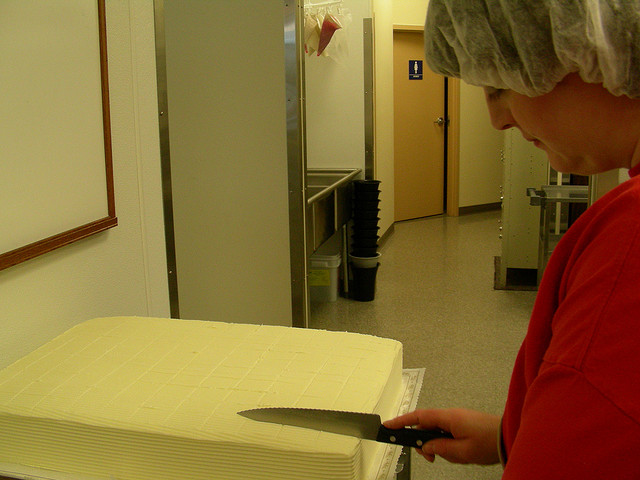


Human reference captions:
- A woman wearing a net on her head cutting a cake. 
- A woman cutting a large white sheet cake.
- A woman wearing a hair net cutting a large sheet cake.
- there is a woman that is cutting a white cake
- A woman marking a cake with the back of a chef's knife. 


In [5]:
from io import BytesIO
from urllib.request import urlopen

from IPython.display import display

try:
    from PIL import Image
except ImportError:
    raise ImportError(
        "Pillow is required. Run %pip install Pillow in a separate cell, "
        "then rerun this cell."
    ) from None

example = candidate_images[0]

# Download into memory only; no image files are saved.
with urlopen(example["coco_url"], timeout=30) as response:
    image_bytes = response.read()

with Image.open(BytesIO(image_bytes)) as image:
    image.load()
    print("Downloaded dimensions:", image.size)
    print("Metadata dimensions:", (example["width"], example["height"]))
    display(image)

print("\nHuman reference captions:")
for caption in captions:
    if caption["image_id"] == example["id"]:
        print("-", caption["caption"])


### Interpretation

Downloaded and recorded dimensions both equal **640 × 480**. Five captions broadly
agree on a person wearing a hairnet with a large white cake. Some say *cutting*,
while another says *marking* with the back of a knife. This is a concrete reminder
that human references vary in precision; they are useful supervision, not
unquestionable labels for every detail. The photograph is an access example, not a
model-generated result.


## 5. Final-test pool feasibility: metadata only

**Purpose:** determine whether enough separately sourced final-test candidates
exist without examining their photographs or caption text.

**Input:** validation annotation JSON from the ZIP.  
**Output:** overall validation image count and count with recorded license ID 4.

**Important distinction:** `json.load` parses the entire JSON, including captions,
into memory temporarily. The code only inspects the `images` entries and prints
counts; it does not display captions or use them for training, prompt selection, or
model selection. Deleting the parsed object is housekeeping, not a security seal.
Final-test IDs, duplicate checks, eligibility rules, and an immutable split manifest
still need to be established.


In [6]:
# Parse the JSON, but inspect only image/license metadata; do not display captions.
with ZipFile("annotations_trainval2017.zip") as archive:
    with archive.open("annotations/captions_val2017.json") as file:
        validation_metadata = json.load(file)

test_candidates = [
    image
    for image in validation_metadata["images"]
    if image["license"] == 4
]

print(f"Validation images: {len(validation_metadata['images']):,}")
print(f"CC BY final-test candidates: {len(test_candidates):,}")

# Keep reference captions out of subsequent exploratory work.
del validation_metadata


Validation images: 5,000
CC BY final-test candidates: 857


### Interpretation

There are **857 recorded CC BY candidates among 5,000 validation images**. Revise
the earlier 1,000-image final-test proposal to **up to 857**. Final availability and
cross-split duplicate checks may reduce that count. This is a proposed custom
subset, not the official COCO benchmark test split.


## 6. Caption-model runtime feasibility

### 6.1 Basic MPS computation and gradients

**Input:** a random 4 × 4 tensor on the Mac GPU.  
**Output:** MPS availability, finite scalar loss, and finite gradients.  
**Acceptance:** all checks true. This is a device smoke check, not model training.


In [7]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS built:", torch.backends.mps.is_built())
print("MPS available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    # Check both GPU computation and gradient calculation.
    x = torch.randn(4, 4, device="mps", requires_grad=True)
    loss = x.square().mean()
    loss.backward()

    print("Device:", x.device)
    print("Finite loss:", torch.isfinite(loss).item())
    print("Finite gradients:", torch.isfinite(x.grad).all().item())


PyTorch: 2.15.0
Torchvision: 0.29.2
MPS built: True
MPS available: True
Device: mps:0
Finite loss: True
Finite gradients: True


In [8]:
if not torch.backends.mps.is_available():
    raise RuntimeError("These feasibility checks require the target Mac's MPS device.")

device = torch.device("mps")


### 6.2 Random-weight encoder shape check

**Purpose:** isolate encoder layout/device compatibility before using pretrained weights.

**Input:** one random RGB tensor of shape `(1, 3, 224, 224)`.  
**Output:** feature grid `(1, 512, 7, 7)` and visual-token sequence `(1, 49, 512)`.
Removing pooling and the classifier retains spatial features. Flattening the 7 × 7
positions yields 49 tokens; those positions are **not detected objects**.
`eval()` fixes evaluation behavior, including batch normalization; freezing parameters
prevents gradient training. Random weights provide no evidence of image understanding.


In [9]:
from torch import nn
from torchvision.models import resnet18

# Random weights are sufficient for this shape/device test.
encoder = resnet18(weights=None)

# Remove global pooling and classification, retaining spatial features.
feature_extractor = nn.Sequential(
    *list(encoder.children())[:-2]
).to("mps").eval()

# Freeze the extractor, matching our proposed training design.
feature_extractor.requires_grad_(False)

dummy_image = torch.randn(1, 3, 224, 224, device="mps")

with torch.inference_mode():
    feature_grid = feature_extractor(dummy_image)

    # Turn the spatial grid into a sequence for decoder cross-attention.
    visual_tokens = feature_grid.flatten(2).transpose(1, 2)

print("Feature grid:", tuple(feature_grid.shape))
print("Visual tokens:", tuple(visual_tokens.shape))
print("Finite features:", torch.isfinite(visual_tokens).all().item())
print(
    "Trainable extractor parameters:",
    sum(p.numel() for p in feature_extractor.parameters() if p.requires_grad),
)


Feature grid: (1, 512, 7, 7)
Visual tokens: (1, 49, 512)
Finite features: True
Trainable extractor parameters: 0


### 6.3 Minimal decoder forward/backward check

**Input:** synthetic features for two images and six caption input positions,
with a 100-token synthetic vocabulary.  
**Architecture:** trainable 512→256 visual projection; token and learned position
embeddings; two Transformer decoder blocks; four heads; feed-forward width 1,024;
zero dropout for this smoke check; vocabulary projection.  
**Output:** logits `(2, 6, 100)`, finite loss, and present/finite gradients.

Shifting a token sequence creates next-token inputs/targets. The boolean upper
triangular mask blocks future caption positions; cross-attention can use visual
memory. This code demonstrates successful computation, **not** a behavioral test
that the causal mask prevents leakage. There are no padded sequences here, so
padding masks and ignored-padding loss remain untested. No optimizer update occurs
in this check, and no real captions are trained.


In [10]:
# Small synthetic batch: two images and six caption tokens per image.
device = torch.device("mps")
batch_size = 2
sequence_length = 6
vocabulary_size = 100
model_width = 256

visual_projection = nn.Linear(512, model_width).to(device)
token_embedding = nn.Embedding(vocabulary_size, model_width).to(device)
position_embedding = nn.Embedding(sequence_length, model_width).to(device)

decoder_layer = nn.TransformerDecoderLayer(
    d_model=model_width,
    nhead=4,
    dim_feedforward=1024,
    dropout=0.0,
    batch_first=True,
)
decoder = nn.TransformerDecoder(decoder_layer, num_layers=2).to(device)
output_head = nn.Linear(model_width, vocabulary_size).to(device)

# Mimic the frozen encoder's output: 49 spatial tokens per image.
visual_features = torch.randn(batch_size, 49, 512, device=device)
memory = visual_projection(visual_features)

# Shift one sequence to create next-token inputs and targets.
token_ids = torch.randint(
    0, vocabulary_size, (batch_size, sequence_length + 1), device=device
)
input_ids = token_ids[:, :-1]
target_ids = token_ids[:, 1:]

positions = torch.arange(sequence_length, device=device)
embedded_tokens = (
    token_embedding(input_ids) + position_embedding(positions)
)

# True blocks attention to future caption positions.
causal_mask = torch.triu(
    torch.ones(
        sequence_length, sequence_length, dtype=torch.bool, device=device
    ),
    diagonal=1,
)

decoded = decoder(
    tgt=embedded_tokens,
    memory=memory,
    tgt_mask=causal_mask,
)
logits = output_head(decoded)

loss = nn.functional.cross_entropy(
    logits.reshape(-1, vocabulary_size),
    target_ids.reshape(-1),
)
loss.backward()

modules = [
    visual_projection,
    token_embedding,
    position_embedding,
    decoder,
    output_head,
]
parameters = [
    parameter
    for module in modules
    for parameter in module.parameters()
    if parameter.requires_grad
]

print("Logits shape:", tuple(logits.shape))
print("Finite loss:", torch.isfinite(loss).item())
print("All gradients present:", all(p.grad is not None for p in parameters))
print(
    "All gradients finite:",
    all(
        p.grad is not None and torch.isfinite(p.grad).all().item()
        for p in parameters
    ),
)


Logits shape: (2, 6, 100)
Finite loss: True
All gradients present: True
All gradients finite: True


### 6.4 Release synthetic smoke-check objects

The original session used kernel restarts. For sequential execution, explicitly
release the preceding model/tensor references before constructing the pretrained
extractor. This housekeeping cell is new and has no retained output. It does not
change any model architecture or optimizer setting. Emptying the MPS cache only
releases unused cached allocations, not live tensor storage.


In [11]:
import gc

# Remove live references, including lists that retain model parameters.
for object_name in ('encoder',
 'feature_extractor',
 'dummy_image',
 'feature_grid',
 'visual_tokens',
 'x',
 'loss',
 'visual_projection',
 'token_embedding',
 'position_embedding',
 'decoder_layer',
 'decoder',
 'output_head',
 'visual_features',
 'memory',
 'token_ids',
 'input_ids',
 'target_ids',
 'positions',
 'embedded_tokens',
 'causal_mask',
 'decoded',
 'logits',
 'modules',
 'parameters'):
    globals().pop(object_name, None)

gc.collect()
torch.mps.empty_cache()


### 6.5 Pretrained encoder on a real training photograph

**Input:** ImageNet-pretrained `ResNet18_Weights.IMAGENET1K_V1` and training image
522418, already inspected above.  
**Output:** normalized input `(1, 3, 224, 224)`, finite visual tokens `(1, 49, 512)` on MPS.

The first execution may download approximately 45 MB of weights to the normal
Torch cache. `progress=False` suppresses that download's progress display.
The official weight transform resizes, center-crops to 224 × 224, and applies the
weight-specific normalization. **Center cropping can remove caption-relevant
content**; a scene-preserving preprocessing choice must be decided before training.
This cell checks pretrained feature extraction, not recognition or caption accuracy.
Record pretrained-weight terms separately before public artifact distribution.


In [12]:
from io import BytesIO
from urllib.request import urlopen

import torch
from PIL import Image
from torch import nn
from torchvision.models import ResNet18_Weights, resnet18

device = torch.device("mps")
weights = ResNet18_Weights.IMAGENET1K_V1

# Reuse pretrained visual features, excluding pooling and classification.
encoder = resnet18(weights=weights, progress=False)
feature_extractor = nn.Sequential(
    *list(encoder.children())[:-2]
).to(device).eval()
feature_extractor.requires_grad_(False)

# Reuse the inspected training image; no final-test image is accessed.
image_url = "http://images.cocodataset.org/train2017/000000522418.jpg"
with urlopen(image_url, timeout=30) as response:
    image_bytes = response.read()

with Image.open(BytesIO(image_bytes)) as image:
    image_tensor = weights.transforms()(image.convert("RGB"))

image_batch = image_tensor.unsqueeze(0).to(device)

with torch.inference_mode():
    feature_grid = feature_extractor(image_batch)
    visual_tokens = feature_grid.flatten(2).transpose(1, 2)

print("Weights:", weights.name)
print("Input shape:", tuple(image_batch.shape))
print("Visual tokens:", tuple(visual_tokens.shape))
print("Finite features:", torch.isfinite(visual_tokens).all().item())
print("Device:", visual_tokens.device)


Weights: IMAGENET1K_V1
Input shape: (1, 3, 224, 224)
Visual tokens: (1, 49, 512)
Finite features: True
Device: mps:0


## 7. Synthetic decoder training-cost benchmark

**Purpose:** estimate decoder computation cost using cached-feature-shaped inputs.

| Setting | Value |
|---|---|
| Batch size | 32 caption sequences |
| Caption input length | 40 tokens, with no padding |
| Synthetic vocabulary | 8,000 |
| Visual memory | 49 × 512 features per image |
| Decoder | Width 256; 2 blocks; 4 heads; feed-forward width 1,024 |
| Dropout | 0.1 |
| Optimizer | AdamW, learning rate 0.0003; other settings use installed defaults |
| Warmup / measured steps | 5 / 20 |
| Precision | float32 |

**Input:** the same synthetic batch repeatedly.  
**Output:** synchronized average step time, sequence throughput, finite final loss,
and current MPS tensor allocation.

Timing includes forward pass, cross-entropy, backward pass, and optimizer update.
It excludes image-feature extraction, feature-cache loading, real caption batching,
validation, checkpoints, and application inference. Repeated synthetic inputs and
short measurement duration make this an optimistic planning observation, not a
throughput guarantee. No training seed was recorded. The diagnostic uses a small
vocabulary in Section 6.3; this larger benchmark uses the proposed vocabulary cap.


In [13]:
import time

batch_size = 32
sequence_length = 40
vocabulary_size = 8_000
model_width = 256

benchmark_model = nn.ModuleDict({
    "visual_projection": nn.Linear(512, model_width),
    "token_embedding": nn.Embedding(vocabulary_size, model_width),
    "position_embedding": nn.Embedding(sequence_length, model_width),
    "decoder": nn.TransformerDecoder(
        nn.TransformerDecoderLayer(
            d_model=model_width,
            nhead=4,
            dim_feedforward=1024,
            dropout=0.1,
            batch_first=True,
        ),
        num_layers=2,
    ),
    "output_head": nn.Linear(model_width, vocabulary_size),
}).to(device).train()

optimizer = torch.optim.AdamW(
    benchmark_model.parameters(), lr=3e-4
)

# Synthetic cached features and shifted next-token targets.
features = torch.randn(batch_size, 49, 512, device=device)
tokens = torch.randint(
    vocabulary_size,
    (batch_size, sequence_length + 1),
    device=device,
)
positions = torch.arange(sequence_length, device=device)
causal_mask = torch.triu(
    torch.ones(
        sequence_length, sequence_length,
        dtype=torch.bool, device=device,
    ),
    diagonal=1,
)


def benchmark_step():
    """Run one optimizer update for the fixed synthetic benchmark batch.

    Parameters
    ----------
    None
        Uses benchmark_model, optimizer, features, tokens, positions,
        causal_mask, and vocabulary_size defined in this section.

    Returns
    -------
    torch.Tensor
        Detached scalar cross-entropy loss on MPS; no graph is retained.

    Side effects
    ------------
    Clears gradients and updates benchmark model parameters and optimizer
    state. It does not update the frozen image encoder or use real captions.
    """
    optimizer.zero_grad(set_to_none=True)

    memory = benchmark_model["visual_projection"](features)
    embedded = (
        benchmark_model["token_embedding"](tokens[:, :-1])
        + benchmark_model["position_embedding"](positions)
    )
    decoded = benchmark_model["decoder"](
        embedded, memory, tgt_mask=causal_mask
    )
    logits = benchmark_model["output_head"](decoded)

    loss = nn.functional.cross_entropy(
        logits.reshape(-1, vocabulary_size),
        tokens[:, 1:].reshape(-1),
    )
    loss.backward()
    optimizer.step()
    return loss.detach()


# Warm up GPU execution and initialize optimizer state before timing.
for _ in range(5):
    benchmark_step()

torch.mps.synchronize()
started = time.perf_counter()

timed_steps = 20
for _ in range(timed_steps):
    benchmark_loss = benchmark_step()

torch.mps.synchronize()
seconds_per_step = (time.perf_counter() - started) / timed_steps

print(f"Seconds per training step: {seconds_per_step:.3f}")
print(f"Caption sequences/second: {batch_size / seconds_per_step:.1f}")
print("Final loss finite:", torch.isfinite(benchmark_loss).item())
print(
    "Current MPS tensor memory (GiB):",
    round(torch.mps.current_allocated_memory() / 1024**3, 2),
)


Seconds per training step: 0.013
Caption sequences/second: 2542.8
Final loss finite: True
Current MPS tensor memory (GiB): 0.14


### Interpretation and limits

Historical result: **0.013 seconds/step**, **2,556.3 caption sequences/second**,
finite loss, and **0.14 GiB current MPS tensor allocation**. The first printed value
is rounded; use the unrounded `seconds_per_step` when computing throughput.

For 16,000 images with approximately five captions each, 80,000 sequences at batch
size 32 mean about 2,500 steps, or roughly **33 seconds of decoder computation per
epoch** at the observed rate. This excludes all other work; it is not an expected
real epoch time. Actual training must be measured with real batches.

The memory API reports current live tensor allocation, **not peak memory, allocator
reserve, total process memory, or macOS memory pressure**. No peak-memory or Activity
Monitor result is recorded in this notebook. Real-data timing and memory gates remain open.


### 7.1 Release caption-check resources before the storyteller

This new housekeeping cell replaces the original restart between experiments.
It releases encoder, decoder benchmark, optimizer, and graph references so that
model components are not unnecessarily resident together. No model artifacts are
saved or trained caption checkpoints claimed by this notebook.


In [14]:
for object_name in ('encoder',
 'feature_extractor',
 'dummy_image',
 'feature_grid',
 'visual_tokens',
 'x',
 'loss',
 'visual_projection',
 'token_embedding',
 'position_embedding',
 'decoder_layer',
 'decoder',
 'output_head',
 'visual_features',
 'memory',
 'token_ids',
 'input_ids',
 'target_ids',
 'positions',
 'embedded_tokens',
 'causal_mask',
 'decoded',
 'logits',
 'modules',
 'parameters',
 'benchmark_model',
 'optimizer',
 'features',
 'tokens',
 'benchmark_loss',
 'benchmark_step',
 'image_batch',
 'image_tensor'):
    globals().pop(object_name, None)

gc.collect()
torch.mps.empty_cache()


## 8. Local storyteller feasibility

### 8.1 Download incident and recovered loading procedure

The original in-notebook download stalled near 85%. Its traceback reported
`zmq.error.ZMQError: Too many open files` while Hugging Face Xet progress updates
passed through tqdm notebook widgets and Jupyter sockets. This identifies where
failure surfaced; it does not establish the underlying file-handle exhaustion cause.
The repeated traceback and incomplete widget state are omitted from the cleaned notebook.

Recovery used a separate Terminal after shutting down the affected kernel:

```bash
cd ~/Projects/image-inspired-story-creator
source .venv/bin/activate
hf download Qwen/Qwen2.5-1.5B-Instruct model.safetensors
```

That command completed using the existing cache. Progress widgets are disabled in
the first notebook cell. No token, cache deletion, global package reinstall, or
system-wide file-limit change was needed for the successful recovery.

### 8.2 Load the pinned cached model

**Input:** Qwen2.5-1.5B-Instruct at revision
`989aa7980e4cf806f80c7fef2b1adb7bc71aa306`, already cached with its tokenizer/config files.  
**Output:** device, dtype, revision, and cached load duration.

`local_files_only=True` forbids network fallback: a missing file raises an error.
On another machine, use the CLI to cache this exact revision and required files
before running the cell:

```bash
hf download Qwen/Qwen2.5-1.5B-Instruct --revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306 --include '*.json' '*.txt' 'model.safetensors'
```

The whole-model weights are approximately 3.09 GB. The storyteller is a **reused,
pretrained application component**, frozen for inference, not the student's trained
generative-model contribution. The historical load was 3.5 seconds; that excludes
network download and does not establish typical cold-start latency.


In [15]:
import time

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

story_model_id = "Qwen/Qwen2.5-1.5B-Instruct"
story_revision = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"

started = time.perf_counter()

story_tokenizer = AutoTokenizer.from_pretrained(
    story_model_id,
    revision=story_revision,
    local_files_only=True,
)

# Load cached weights only, then place the model on the Mac GPU.
story_model = AutoModelForCausalLM.from_pretrained(
    story_model_id,
    revision=story_revision,
    local_files_only=True,
    dtype=torch.float16,
    use_safetensors=True,
    trust_remote_code=False,
).to("mps").eval()

story_model.requires_grad_(False)
torch.mps.synchronize()

print("Device:", next(story_model.parameters()).device)
print("Weight dtype:", next(story_model.parameters()).dtype)
print("Revision:", story_revision)
print(f"Cached load time: {time.perf_counter() - started:.1f} seconds")


W1111 08:11:40.700000 24553 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps:0
Weight dtype: torch.float16
Revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Cached load time: 2.4 seconds


### 8.3 Revised development prompt

**Input:** one explicitly approved text premise. No photograph, image features,
original caption, or other hidden scene information is passed to the storyteller.
The prompt asks for 115–130 words as a working target within the product's
100–150-word limit, explicit detail retention, and a goal/complication/resolution.
These are requested behaviors, not guarantees.

The uploaded notebook's revised system prompt originally appeared *after* the
generation cell, despite being executed before its retained output. This cleanup
places the complete revised prompt below **before** generation, fixing that hidden
state dependency. The initial prompt is documented as a prior experiment rather
than left as an active assignment that can overwrite the revised prompt.


In [16]:
approved_premise = (
    "A person wearing a hairnet prepares to cut a large white cake."
)

messages = [
    {
        "role": "system",
        "content": (
            "Write one complete fictional story in English, targeting 115–130 words "
            "and never exceeding 150 words. Return only the story, without a title. "
            "Explicitly retain every concrete detail in the approved premise, "
            "including clothing, objects, and actions. "
            "Give the main character a small goal, introduce one complication, "
            "and end with a clear resolution. "
            "Avoid repeated descriptions and contradictory details. "
            "You may invent names, dialogue, motives, and backstory."
        ),
    },
    {
        "role": "user",
        "content": f"Approved premise:\n{approved_premise}",
    },
]


### 8.4 Generate and inspect the revised story

**Input:** the revised `messages`, cached tokenizer, and frozen story model.  
**Output:** decoded story, whitespace word count, length pass/fail, synchronized
generation duration, generated token count, and token-limit flag.

The model's own chat template formats the messages. Greedy decoding
(`do_sample=False`) avoids sampling for this comparison; `max_new_tokens=300`
bounds generation but does not enforce word count. Only new tokens are decoded,
excluding the input prompt. Hitting the limit indicates possible truncation;
not hitting it does not by itself prove a coherent ending.

Word count uses `len(story.split())`. Times are individual requests and include
first-use effects; they are not p95 measurements. The fiction label is rendered by
our code rather than entrusted to the language model.


In [17]:
# Apply the model's chat format, then move input tensors to its device.
prompt = story_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)
inputs = story_tokenizer(prompt, return_tensors="pt").to("mps")

torch.mps.synchronize()
started = time.perf_counter()

with torch.inference_mode():
    generated_ids = story_model.generate(
        **inputs,
        max_new_tokens=300,
        do_sample=False,
        pad_token_id=story_tokenizer.eos_token_id,
    )

torch.mps.synchronize()
elapsed = time.perf_counter() - started

# Remove prompt tokens so only the newly generated story is decoded.
new_tokens = generated_ids[0, inputs["input_ids"].shape[1]:]
story = story_tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

# Initial word-count convention: whitespace-separated words.
word_count = len(story.split())

print("FICTIONAL STORY\n")
print(story)
print(f"\nWords: {word_count}")
print(f"Within 100–150 words: {100 <= word_count <= 150}")
print(f"Generation time: {elapsed:.2f} seconds")
print(f"Generated tokens: {new_tokens.numel()}")
print(f"Reached token limit: {new_tokens.numel() == 300}")


FICTIONAL STORY

The baker, dressed in a white apron and hairnet, carefully measured the ingredients for the cake. She had been working on this for hours, her hands stained with flour and sugar. Just as she was about to cut the cake, a sudden gust of wind blew in, causing the cake to wobble precariously. The baker, with a mix of relief and worry, quickly grabbed the cake and ran to the back of the kitchen, where she placed it on a sturdy table. She then turned to face the window, her eyes wide with determination. "I'll just have to make sure it's perfectly centered," she said to herself, as she began to cut the cake, her hands steady and her heart pounding with anticipation.

Words: 123
Within 100–150 words: True
Generation time: 1.96 seconds
Generated tokens: 150
Reached token limit: False


### 8.5 Observed quality and comparison provenance

| Check | Revised saved sample |
|---|---|
| Length | 123 words; passes the 100–150 bound |
| Generation duration | 2.01 seconds; 150 generated tokens |
| Token-limit truncation | Limit not reached |
| Hairnet retained | Yes |
| Large white cake retained | Incomplete: size and color omitted |
| Narrative logic | Weak: ingredient measurement for a finished cake; running with a wobbling cake |
| Resolution | Partial; starts cutting without a convincing resolution of the complication |

The original notebook summary records an earlier generation at **3.44 seconds**
that exceeded the word limit and contained contradictions. The author reported
154 words during the working session, but that first generation's complete output
was overwritten and is **not retained in the uploaded file**. Treat that summary
as recorded experiment history, not a second independently inspectable sample.

The original prompt was:

> Write a fictional story of 100–150 words in English. Preserve the explicit facts
> in the supplied premise. You may invent names, dialogue, motives, and backstory.
> Return only the story, without a title or commentary.

Only the system prompt was deliberately revised; the premise, pinned model,
greedy decoding, and 300-token cap were kept fixed. No causal quality claim can be
established from one output per prompt. Do not continue ad hoc prompt tuning here.
The model is technically runnable but remains provisional pending a fixed story
review suite, edit-control cases, and independent assessment of caption quality.


## 9. Feasibility findings and remaining gates

| Area | Evidence | Decision |
|---|---|---|
| Environment | Native arm64 `.venv`; imports and MPS checks pass; terminal dependency check clean | Initial compatibility supported |
| Training data | 19,470 recorded CC BY images / 97,410 captions | Adequate candidate pool; rights ledger and data audit unfinished |
| Final-test pool | 857 recorded CC BY candidates from val2017 | Feasible provisional pool; no final split assigned |
| Image access | One training image downloads/decodes with matching dimensions | Single-example access passes; bulk reliability unknown |
| Pretrained visual features | Finite `(1, 49, 512)` MPS tensor | Feature execution passes; caption accuracy untested |
| Decoder | Synthetic forward/backward gradients and optimizer benchmark pass | Computation promising; real training untested |
| Story model | Pinned cached model loads and generates locally | Runtime passes; quality and reliability unproven |
| Application | Gradio imports only | UI, state, errors, and deployment not implemented |

### Proposed data allocation — not yet created

| Role | Proposed size | Source |
|---|---:|---|
| Training | 16,000 | train2017 recorded CC BY pool |
| Checkpoint validation | 2,000 | Disjoint train2017 recorded CC BY pool |
| Fixed development review | 200 | Disjoint train2017 recorded CC BY pool |
| Reserve | 1,270 | Remaining train2017 candidates |
| Final test | Up to 857 | val2017 recorded CC BY pool |

Do not split captions independently of images. Group duplicates before assignment,
fit the vocabulary only on training captions, retain all captions with their image,
and keep final-test content out of selection and prompt tuning. Candidate counts
can shrink after download, attribution, and duplicate checks. No sealed manifest,
content hashes, or split seed has yet been produced.

### Open gates before full training or release

1. Record the complete project/rubric mapping and resolve any remaining course-tool
   or pretrained-component ambiguity. This notebook does not guarantee grading outcomes.
2. Review image and pretrained-weight terms, complete attribution records for public
   examples, audit selection bias, and verify dataset download integrity.
3. Choose scene-preserving preprocessing and define caption tokenization, vocabulary,
   padding, and sequence-length policy from training data.
4. Test causal/padding-mask behavior, tiny-subset overfit, checkpoint reload, and
   meaningful image conditioning. Finite gradients alone are insufficient.
5. Measure real-data throughput, end-to-end epoch cost, peak process/MPS memory,
   and macOS memory pressure. Synthetic timing alone does not meet the compute gate.
6. Establish the fixed review sets, caption retrieval baseline, failure categories,
   measurable acceptance criteria, and experiment stopping rules before tuning.
7. Evaluate stories independently from captions, using both corrected premises and
   generated captions; test that edits affect only the current approved premise.
8. Implement stale-story behavior: premise changes mark the old story outdated;
   regeneration is required, including when a response finishes after another edit.
9. Record the accepted local-browser launch scope and establish focused Git branches,
   milestone commits, and reviewed merges before substantial implementation.

### Short conclusion

COCO provides a structurally sound human-caption dataset with a sufficiently large
recorded CC BY candidate pool for the proposed small-scale project. Native MPS
execution works for pretrained image features and synthetic Transformer decoder
computation, but real caption training and peak memory remain untested. A pinned
pretrained storyteller runs locally, while its saved sample demonstrates concrete
premise-retention and narrative-quality limitations. The evidence supports continued
bounded feasibility work, not a claim of a trained caption generator or launch-ready
application. Preserve the completed VAE repository as a separate project.

## 10. Reference links and attribution notes

These sources support external dataset, license, model, and API descriptions;
counts, timings, examples, and interpretations above come from the author's own
runs and do not require external citations. This notebook is a feasibility record,
not the final APA report. The report must use the supplied APA template and include
at least two credible sources, including a scholarly source, with matching in-text
citations and references tied to the implementation actually delivered.

- COCO Consortium. Dataset downloads and format:
  https://cocodataset.org/#download and https://cocodataset.org/#format-data
- COCO Consortium. Terms of use:
  https://cocodataset.org/dataset/termsofuse.htm
- Creative Commons. Attribution 2.0 Generic:
  https://creativecommons.org/licenses/by/2.0/
- PyTorch / Torchvision. ResNet18 weights and preprocessing:
  https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html
- PyTorch / Torchvision. Pretrained-weight terms notice:
  https://docs.pytorch.org/vision/stable/models.html
- PyTorch. MPS backend:
  https://docs.pytorch.org/docs/stable/notes/mps.html
- Qwen Team. Qwen2.5-1.5B-Instruct model card and license:
  https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct
- Hugging Face. Download CLI and environment variables:
  https://huggingface.co/docs/huggingface_hub/guides/cli and
  https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables

**Cleanup disclosure:** AI assistance was used to organize and document this
notebook. Existing local results were preserved; edited code and new housekeeping
cells require review and a clean rerun by the author before committing them as
reproduced evidence.


### Image attribution

**“Rachel”** by [Tracy Hunter](https://www.flickr.com/photos/tracyhunter/), licensed under [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/).

[Original photograph](https://www.flickr.com/photos/tracyhunter/127244861/)
· COCO image ID: `522418`.

The source photograph is displayed without intentional edits. The separate encoder input is resized, center-cropped, and normalized.

The photographer's description identifies the action as scoring the frosting for portion control. Some reference captions describe cutting instead, illustrating variation in the precision of human annotations.